In [21]:
import json
import re
from konlpy.tag import Okt
from kiwipiepy import Kiwi
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
from wordcloud import WordCloud
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import matplotlib

In [22]:
#1번-1
inputFileName = r"./8장_data/data_analysis_job_postings.csv"
data = pd.read_csv(inputFileName, encoding='utf-8')
data.head(0)

,posting_id,company,job,industry,region,experience,required_years,salary,education,employment_type,remote_type,company_size,skill,posting_date,posting_month,deadline_days,openings,applicants,welfare_score,description


In [23]:
#1번-2
len(data)

2020

In [24]:
#1번-3
data.shape

(2020, 20)

In [25]:
#1번-4
data.dtypes

posting_id         object
company            object
job                object
industry           object
region             object
experience         object
required_years      int64
salary             object
education          object
employment_type    object
remote_type        object
company_size       object
skill              object
posting_date       object
posting_month      object
deadline_days       int64
openings            int64
applicants         object
welfare_score      object
description        object
dtype: object

In [26]:
#1번-5
data.isnull().sum()

posting_id          0
company             0
job                 0
industry            0
region              0
experience         30
required_years      0
salary             19
education          30
employment_type     0
remote_type         0
company_size        0
skill               0
posting_date        0
posting_month       0
deadline_days       0
openings            0
applicants         18
welfare_score      35
description         0
dtype: int64

In [27]:
#1번-6
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2020 entries, 0 to 2019
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   posting_id       2020 non-null   object
 1   company          2020 non-null   object
 2   job              2020 non-null   object
 3   industry         2020 non-null   object
 4   region           2020 non-null   object
 5   experience       1990 non-null   object
 6   required_years   2020 non-null   int64 
 7   salary           2001 non-null   object
 8   education        1990 non-null   object
 9   employment_type  2020 non-null   object
 10  remote_type      2020 non-null   object
 11  company_size     2020 non-null   object
 12  skill            2020 non-null   object
 13  posting_date     2020 non-null   object
 14  posting_month    2020 non-null   object
 15  deadline_days    2020 non-null   int64 
 16  openings         2020 non-null   int64 
 17  applicants       2002 non-null   

In [28]:
#2번-1 결측치 처리
data_clean = data.dropna()
data_clean.isnull().sum()

posting_id         0
company            0
job                0
industry           0
region             0
experience         0
required_years     0
salary             0
education          0
employment_type    0
remote_type        0
company_size       0
skill              0
posting_date       0
posting_month      0
deadline_days      0
openings           0
applicants         0
welfare_score      0
description        0
dtype: int64

In [29]:
#2번-2 중복제거
data_clean = data_clean.drop_duplicates()

In [30]:
data_clean['posting_date']

0       2026-11-05
1       2026-08-24
2       2026-12-26
3       2026-09-13
4       2026-12-15
           ...    
1994    2026-12-21
1995    2026-06-05
1996    2026-04-08
1997    2026-09-28
1998    2026-03-29
Name: posting_date, Length: 1888, dtype: object

In [48]:
#2번-3 날짜 형식 통일
pattern =r'^\d{4}-\d{2}-\d{2}$'
count_w = 0
count_w = (data_clean['posting_date'].astype(str).str.match(pattern) == False).sum()
data_clean['posting_date'] = pd.to_datetime(data_clean['posting_date'], errors='coerce')
data_clean = data_clean.dropna()
count_w

np.int64(0)

In [32]:
data_clean['region'].value_counts()

region
서울          754
경기          456
부산          107
인천           93
대구           86
대전           64
강원           63
제주           52
광주           51
세종           35
Seoul        11
서울특별시         9
Gyeonggi      8
경기도           6
서울시           4
인천광역시         4
대구광역시         2
부산광역시         1
대전광역시         1
Daejeon       1
제주도           1
Name: count, dtype: int64

In [33]:
#2번-4 지역명 통일
data_clean['region'] = data_clean['region'].str.lower().str.strip()
is_seoul = data_clean['region'].str.contains('서울|seoul', case=False, na=False)
data_clean.loc[is_seoul, 'region'] = '서울'
is_gyung = data_clean['region'].str.contains('경기|gyeonggi', case=False, na=False)
data_clean.loc[is_gyung, 'region'] = '경기'
is_dae = data_clean['region'].str.contains('대구', case=False, na=False)
data_clean.loc[is_dae, 'region'] = '대구'
is_in = data_clean['region'].str.contains('인천', case=False, na=False)
data_clean.loc[is_in, 'region'] = '인천'
is_daej = data_clean['region'].str.contains('대전|daejeon', case=False, na=False)
data_clean.loc[is_daej, 'region'] = '대전'
is_bu = data_clean['region'].str.contains('부산', case=False, na=False)
data_clean.loc[is_bu, 'region'] = '부산'
is_je = data_clean['region'].str.contains('제주', case=False, na=False)
data_clean.loc[is_je, 'region'] = '제주'

In [34]:
data_clean['region'].value_counts()

region
서울    778
경기    470
부산    108
인천     97
대구     88
대전     66
강원     63
제주     53
광주     51
세종     35
Name: count, dtype: int64

In [35]:
stopWords = set(stopwords.words("english"))
lemma = WordNetLemmatizer()

In [36]:
data_clean['skill']

0                               SQL, Excel
1                     Power BI, KPI, Excel
2                           KPI, SQL, 경영분석
3               마케팅 성과분석, Python, SQL, CRM
4                            A/B 테스트, 대시보드
                       ...                
1994                             SQL, 경영분석
1995    Matplotlib, Tableau, Excel, Pandas
1996           SQL, Looker, Tableau, 데이터마트
1997         서비스 지표, A/B 테스트, 대시보드, Python
1998                 마케팅 성과분석, SQL, Python
Name: skill, Length: 1809, dtype: object

In [47]:
#2-5 패스
def clean_and_tokenize(text):
    if pd.isna(text): # 결측치 처리
        return []
    
    # 소문자화 및 동의어/복합어 치환
    t = str(text).lower()
    t = t.replace('파이썬', 'python').replace('태블로', 'tableau').replace('엑셀', 'excel').replace('sql문', 'sql')
    t = t.replace('power bi', 'power_bi').replace('파워 bi', 'power_bi').replace('파워bi', 'power_bi')
    t = t.replace('google analytics', 'google_analytics').replace('scikit learn', 'scikit_learn')
    t = t.replace('머신 러닝', '머신러닝').replace('machine learning', '머신러닝')
    
    # 특수문자 제거 (언더바 _ 살리기)
    cleaned = re.sub(r"[^a-zA-Z가-힣_]+", " ", t)
    
    # 토큰화 -> 불용어 제거 -> 표제어 추출
    tokens = word_tokenize(cleaned)
    stopped = [w for w in tokens if w not in stopWords]
    lemmatized = [lemma.lemmatize(w) for w in stopped]
    
    return lemmatized
data_clean['refined_skill'] = data_clean['skill'].apply(clean_and_tokenize)
print(data_clean[['skill', 'refined_skill']].head())

                        skill                  refined_skill
0                  SQL, Excel                   [sql, excel]
1        Power BI, KPI, Excel         [power_bi, kpi, excel]
2              KPI, SQL, 경영분석               [kpi, sql, 경영분석]
3  마케팅 성과분석, Python, SQL, CRM  [마케팅, 성과분석, python, sql, crm]
4               A/B 테스트, 대시보드                 [b, 테스트, 대시보드]


In [ ]:
# #기술 스택 표기 통일 완료X
skill_alias = {
    "Python": [
        "python", "python3", "파이썬",
    ],

    "SQL": [
        "sql",
        "sql문",
        "structured query language"
    ],

    "Pandas": [
        "pandas",
        "판다스"
    ],

    "Matplotlib": [
        "matplotlib"
    ],

    "통계": [
        "통계",
        "statistics",
        "통계분석"
    ],

    "인사이트": [
        "인사이트"
    ],

    "모델링": [
        "모델링"
    ],

    "Excel": [
        "excel",
        "ms excel",
        "엑셀"
    ],

    "Tableau": [
        "tableau",
        "태블로"
    ],

    "Power BI": [
        "power bi",
        "파워bi"
    ],

    "Looker": [
        "looker"
    ],

    "대시보드": [
        "대시보드"
    ],

    "리포트": [
        "리포트"
    ],

    "KPI": [
        "kpi"
    ],

    "경영분석": [
        "경영분석"
    ],

    "머신러닝": [
        "머신러닝",
        "머신 러닝",
        "machine learning",
        "ml"
    ],

    "TensorFlow": [
        "tensorflow",
        "텐서플로우"
    ],

    "PyTorch": [
        "pytorch",
        "파이토치"
    ],

    "Scikit-Learn": [
        "scikit-learn"
    ],

    "LLM": [
        "llm",
        "large language model"
    ],

    "생성형 AI": [
        "생성형 ai"
    ],

    "Spark": [
        "spark",
        "apache spark",
        "스파크"
    ],

    "Hadoop": [
        "hadoop",
        "Hadoop",
        "하둡"
    ],

    "Hive": [
        "hive"
    ],

    "Airflow": [
        "airflow",
        "Airflow"
    ],

    "ETL": [
        "etl",
        "ETL"
    ],

    "데이터 파이프라인": [
        "데이터 파이프라인"
    ],

    "대용량 데이터": [
        "대용량 데이터"
    ],

    "데이터마트": [
        "데이터마트"
    ],

    "Amplitude": [
        "amplitude"
    ],

    "Google Analytics": [
        "google analytics"
    ],

    "CRM": [
        "crm"
    ],

    "A/B 테스트": [
        "a/b 테스트",
        "A/B 테스트"
    ],

    "서비스 지표": [
        "서비스 지표"
    ],

    "마케팅 성과분석": [
        "마케팅 성과분석"
    ],

    "세그먼트": [
        "세그먼트"
    ],

    "고객 행동 분석": [
        "고객 행동 분석"
    ],

    "고객세분화": [
        "고객세분화"
    ],

    "Retention": [
        "retention",
        "Retention"
    ],

    "Churn 분석": [
        "churn 분석",
        "Churn 분석"
    ],

    "금융 데이터": [
        "금융 데이터"
    ],

    "리스크 분석": [
        "리스크 분석"
    ],

    "리스크 모델": [
        "리스크 모델"
    ],

    "이상탐지": [
        "이상탐지"
    ]
}

alias_to_skill = {}

for skill, aliases in skill_alias.items():
    for alias in aliases:
        alias_to_skill[alias.lower()] = skill

patterns = sorted(
    alias_to_skill.keys(),
    key=len,
    reverse=True
)

regex = re.compile(
    "|".join(re.escape(p) for p in patterns),
    flags=re.IGNORECASE
)

def extract_skill(text):
    if pd.isna(text):
        return []

    text = str(text).lower()
    skills = []

    for m in regex.finditer(text):
        skill = alias_to_skill[m.group().lower()]
        if skill not in skills:
            skills.append(skill)

    skills = sorted(set(skills))
    return ', '.join(skills)


data_clean["skill"] = data_clean["skill"].apply(extract_skill)
data_clean["skill"].value_counts()

skill
Python, SQL                   39
SQL, Tableau                  12
Python, 머신러닝                  12
Excel, SQL, Tableau           12
Python, SQL, Spark            11
                              ..
금융 데이터, 리스크 모델, 이상탐지, 통계       1
Python, 금융 데이터, 리스크 모델, 통계     1
Churn 분석, SQL, Tableau         1
Excel, Looker, SQL, 데이터마트      1
Churn 분석, Retention, 고객세분화     1
Name: count, Length: 554, dtype: int64

In [ ]:
data_clean['skill'].value_counts()

skill
Python, SQL                   39
SQL, Tableau                  12
Python, 머신러닝                  12
Excel, SQL, Tableau           12
Python, SQL, Spark            11
                              ..
금융 데이터, 리스크 모델, 이상탐지, 통계       1
Python, 금융 데이터, 리스크 모델, 통계     1
Churn 분석, SQL, Tableau         1
Excel, Looker, SQL, 데이터마트      1
Churn 분석, Retention, 고객세분화     1
Name: count, Length: 554, dtype: int64

,posting_id,company,job,industry,region,experience,required_years,salary,education,employment_type,...,skill,posting_date,posting_month,deadline_days,openings,applicants,welfare_score,description,month,refined_skill


In [ ]:
data_clean['salary'].value_counts()

salary
5300         81
5200         77
5100         75
5500         69
5400         69
             ..
8400          1
5700~         1
5600~         1
5500~6100     1
3800~4400     1
Name: count, Length: 83, dtype: int64

In [ ]:
#2-6 연봉 컬럼 정리
salary_clean = data_clean['salary'].astype(str).str.split('~').str[0]
salary_clean = salary_clean.str.replace(r'[^\d]', '', regex=True)
salary_numeric = pd.to_numeric(salary_clean, errors='coerce')
data_clean['salary'] = data_clean['salary'].fillna(salary_numeric.mean())

In [ ]:
#2-7 지원자 수 컬럼 정리
app_clean = data_clean['applicants'].astype(str).str.split('~').str[0]
app_clean = app_clean.str.replace(r'[^\d]', '', regex=True)
app_numeric = pd.to_numeric(app_clean, errors='coerce')
data_clean['applicants'] = data_clean['applicants'].fillna(app_numeric.mean())

In [ ]:
data_clean['applicants']

0       106
1       198
2       330
3       239
4        37
       ... 
1994    328
1995    260
1996    240
1997    337
1998    141
Name: applicants, Length: 1809, dtype: object

In [ ]:
#2-9~12 , 3번 description 컬럼 추출
description = ''
all_text = " ".join(data_clean['description'].dropna().astype(str))
description = re.sub(r'[^\w]', ' ', all_text)
description

'비즈니스 의사결정을 위한 데이터 분석  리포트 작성  대시보드 구축 업무를 수행합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  Power BI  KPI  Excel 기반으로 KPI 리포트와 월간 성과 분석 자료를 작성합니다  신규 데이터 분석 과제를 발굴하고 개선안을 제시합니다  사업 성과  매출  비용 데이터를 분석하여 경영진 의사결정을 지원합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  광고 성과와 고객 유입 데이터를 분석하여 마케팅 전략을 개선합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  A B 테스트  대시보드를 활용하여 사용자 행동 데이터를 분석하고 실험 설계를 지원합니다  신규 데이터 분석 과제를 발굴하고 개선안을 제시합니다  AI 서비스 데이터를 분석하고 생성형 AI 기반 업무 자동화를 지원합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  고객 행동 패턴을 분석하고 서비스 개선을 위한 인사이트를 도출합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  비즈니스 의사결정을 위한 데이터 분석  리포트 작성  대시보드 구축 업무를 수행합니다  비즈니스 지표를 이해하고 실행 가능한 인사이트를 제안할 수 있어야 합니다  서비스 지표 분석과 A B 테스트를 통해 제품 개선 방향을 제안합니다  문제 정의 능력과 커뮤니케이션 역량을 중요하게 평가합니다  Python  Scikit Learn  모델링  머신러닝를 활용하여 예측 모델을 개발하고 실험 결과를 분석합니다  신규 데이터 분석 과제를 발굴하고 개선안을 제시합니다  Matplotlib  Pandas  Python를 활용하여 서비스 데이터를 분석하고 주요 지표를 개선합니다  신규 데이터 분석 과제를 발굴하고 개선안을 제시합니다  서비스 지표 분석과 A B 테스트를 통해 제품 개선 방향을 제안합니다  데이터 품질 관리와 반복 업무 자동화 경험이 있으면 우대합니다  KPI  SQL 기반으로 KPI 리포트와 월간 성과 분석 자료를

In [ ]:
kiwi = Kiwi()

description_N = [
    token.form
    for token in kiwi.tokenize(description)
    if token.tag.startswith('N')
]
count = Counter(description_N)
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))
#5-3 기술 스택 보다 비즈니스의 문제를 찾아내고 서비스를 개선하는 사람을 찾고있다.
# 회사 데이터를 잘 분석해서 타 부서의 올바른 의사결정을 내릴 수 있도록 인사이트를 제안한다.

데이터 : 2320
분석 : 2012
업무 : 866
개선 : 800
기반 : 661
활용 : 643
지표 : 643
지원 : 601
비즈니스 : 588
인사이트 : 570
의사 : 543
결정 : 543
관리 : 530
제안 : 458
고객 : 457
품질 : 456
문제 : 445
부서 : 436
리포트 : 403
서비스 : 401


In [38]:
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties( fname = font_path).get_name()
matplotlib.rc('font', family = font_name)

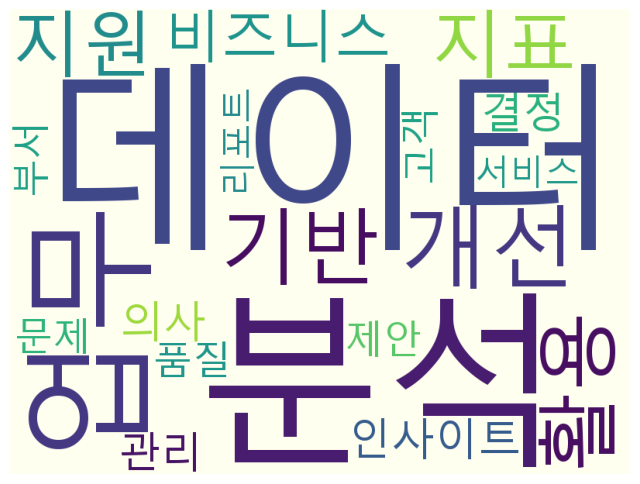

In [ ]:
#4-1 워드클라우드
wc = WordCloud( font_path, background_color = 'ivory', width = 800, height = 600)
cloud = wc.generate_from_frequencies(word_count)
plt.figure(figsize = (8, 8))
plt.imshow(cloud)
plt.axis('off')
plt.show()
#5-1 가장 많이 등장한 키워드
#데이터 분석이 제일 많이 등장한다.

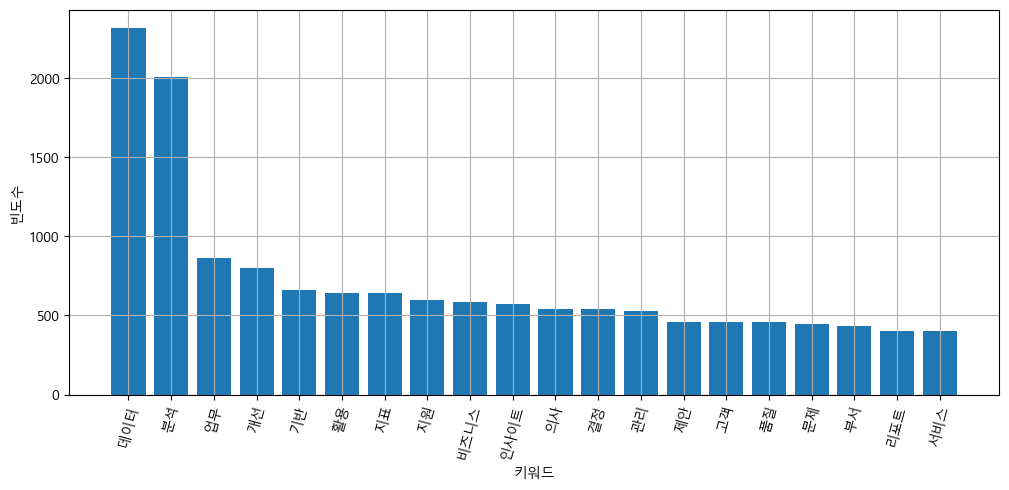

In [ ]:
#4-2 상위 단어 20
plt.figure(figsize = (12, 5))
plt.xlabel('키워드')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

In [ ]:
#4-3 지역별
region = ''
all_region = " ".join(data_clean['region'].dropna().astype(str))
region = re.sub(r'[^\w]', ' ', all_region)

region_N = [
    token.form
    for token in kiwi.tokenize(region)
    if token.tag.startswith('N')
]
count = Counter(region_N)
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

서울 : 778
경기 : 470
부산 : 108
인천 : 97
대구 : 88
대전 : 66
강원 : 63
제주 : 53
광주 : 51
세종 : 35


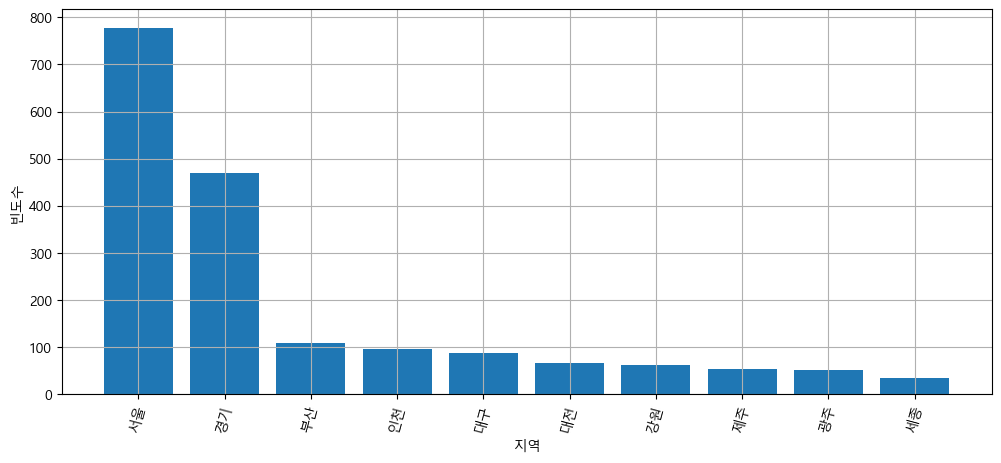

In [ ]:
plt.figure(figsize = (12, 5))
plt.xlabel('지역')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

In [ ]:
#4-4 직무별
job = ''
all_job = " ".join(data_clean['job'].dropna().astype(str))
job = re.sub(r'[^\w]', ' ', all_job)
job_N = [
    token.form
    for token in kiwi.tokenize(job)
    if token.tag.startswith('N')
]
count = Counter(job_N)
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

데이터 : 1526
분석가 : 1521
프로덕트 : 175
마케팅 : 172
사이언티스트 : 154
빅데이터 : 140
엔지니어 : 134
고객 : 124
경영 : 108
금융 : 108
리스크 : 89


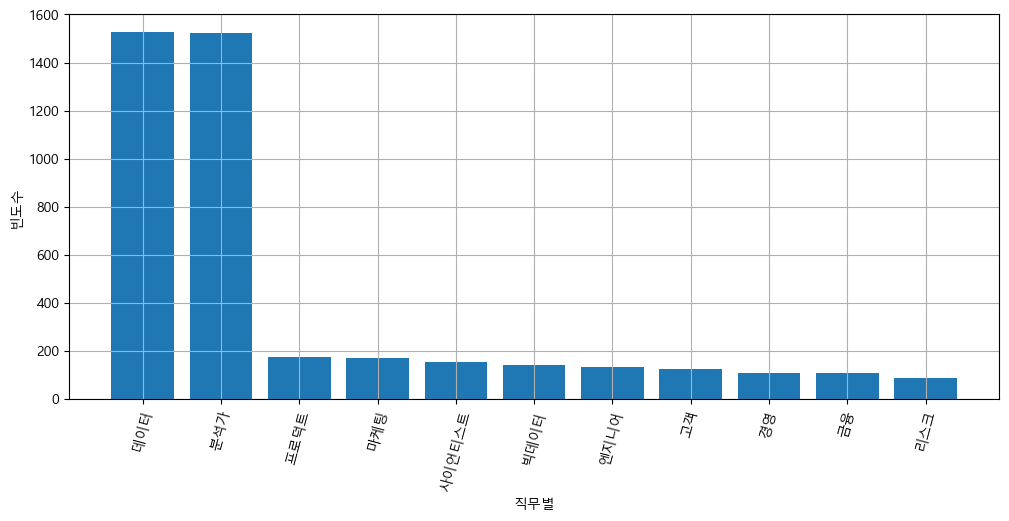

In [ ]:
plt.figure(figsize = (12, 5))
plt.xlabel('직무별')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

In [ ]:
#4-5 산업군별
industry = ''
all_industry = " ".join(data_clean['industry'].dropna().astype(str))
industry = re.sub(r'[^\w]', ' ', all_industry)
industry_N = [
    token.form
    for token in kiwi.tokenize(industry)
    if token.tag.startswith('N')
]
count = Counter(industry_N)
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

커머스 : 171
콘텐츠 : 159
교육 : 155
금융 : 152
통신 : 152
유통 : 150
제조 : 147
게임 : 146
서비스 : 145
모빌리티 : 145
헬스케어 : 145
물류 : 141
IT서비스 : 1


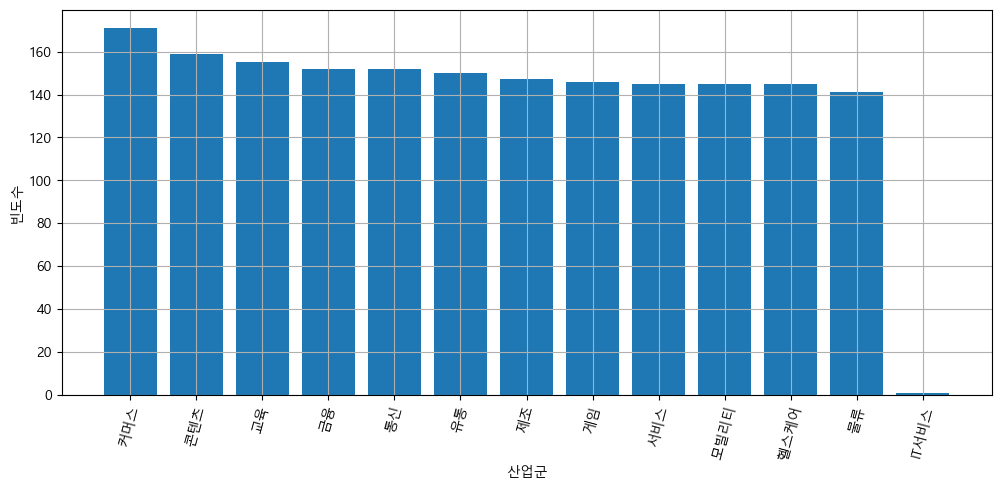

In [ ]:
plt.figure(figsize = (12, 5))
plt.xlabel('산업군')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

In [ ]:
#4-6 경력 수준별
education = ''
all_education = " ".join(data_clean['education'].dropna().astype(str))
education = re.sub(r'[^\w]', ' ', all_education)
education_N = [
    token.form
    for token in kiwi.tokenize(education)
    if token.tag.startswith('N')
]
count = Counter(education_N)
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))
del word_count['이상']

학사 : 1089
석사 : 327
무관 : 288
학력 : 275
박사 : 90
전문 : 88
이상 : 16
전문학사 : 15


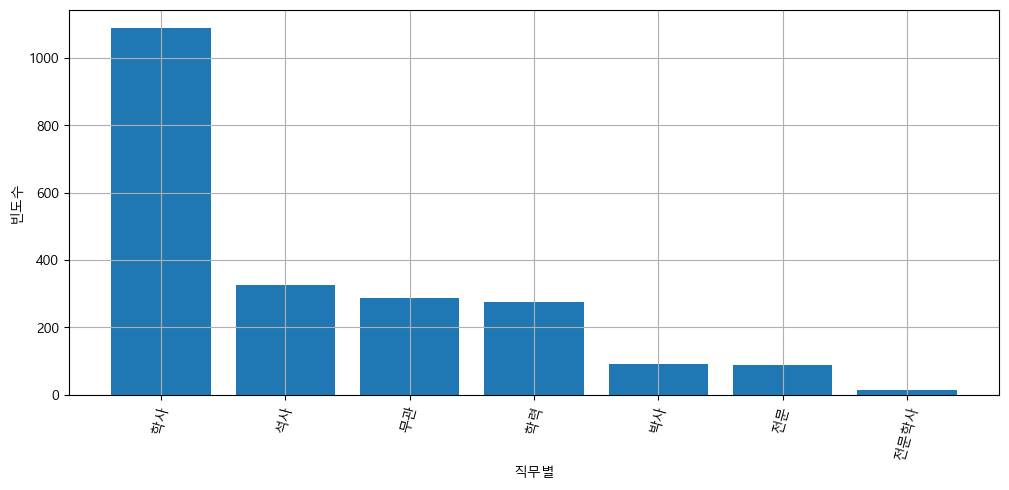

In [ ]:
plt.figure(figsize = (12, 5))
plt.xlabel('직무별')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

In [ ]:
all_skills = " ".join(data_clean['refined_skill'].dropna().astype(str))
skill = re.sub(r'[^\w]', ' ', all_skills)
skill = skill.lower().strip()
Enwords = " ".join(data_clean['refined_skill'].dropna().astype(str))
cleaned_text = re.sub(r"[^a-zA-Z가-힣]+", " ", Enwords)
EnWordsToken = word_tokenize(cleaned_text.lower())
EnWordsTokenStop = [w for w in EnWordsToken if w not in stopWords]
EnWordsTokenStopLemma = [lemma.lemmatize(w) for w in EnWordsTokenStop]
words = EnWordsTokenStopLemma
count = Counter(words)
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

sql : 818
python : 754
tableau : 308
excel : 251
데이터 : 239
테스트 : 183
panda : 179
머신러닝 : 176
분석 : 166
통계 : 164
crm : 146
spark : 145
power : 124
bi : 124
matplotlib : 120
리스크 : 100
금융 : 98
amplitude : 90
마케팅 : 86


In [ ]:
#4-7 기술스택
all_skills = " ".join(data_clean['skill'].dropna().astype(str))
skill = re.sub(r'[^\w]', ' ', all_skills)
skill = skill.lower().strip()
Enwords = " ".join(data_clean['skill'].dropna().astype(str))
cleaned_text = re.sub(r"[^a-zA-Z가-힣]+", " ", Enwords)
EnWordsToken = word_tokenize(cleaned_text.lower())
EnWordsTokenStop = [w for w in EnWordsToken if w not in stopWords]
EnWordsTokenStopLemma = [lemma.lemmatize(w) for w in EnWordsTokenStop]
words = EnWordsTokenStopLemma
count = Counter(words)

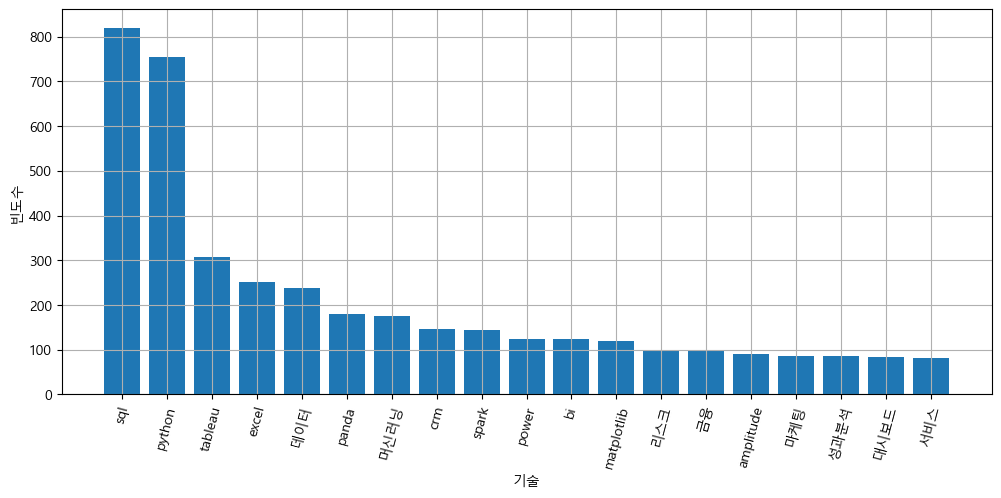

In [ ]:
plt.figure(figsize = (12, 5))
plt.xlabel('기술')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()
#5-2 데이터 분석을 필요로 하는 기업이 많아지면서 sql과 python이 가장 많이 요구된다.
#5-4 필요한 기술 스택들을 확인해보면 필요한 정보를 정확하게 뽑아오는 기술과 그 정보를 활용하는 기술이 중요하며
#또한 데이터를 분석한 결과를 bi를 활용해 자동화 하는 역량이 필요시되고있다.

In [ ]:
del count['테스트']
del count['분석']
del count['통계']

In [ ]:
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

sql : 820
python : 754
tableau : 308
excel : 251
데이터 : 239
panda : 179
머신러닝 : 176
crm : 146
spark : 145
power : 124
bi : 124
matplotlib : 120
리스크 : 100
금융 : 98
amplitude : 90
마케팅 : 86
성과분석 : 86
대시보드 : 84
서비스 : 82


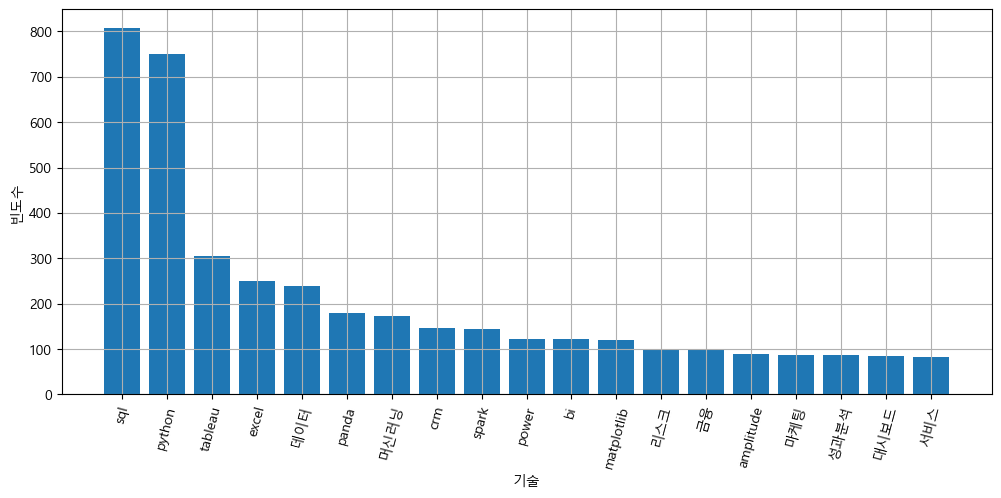

In [ ]:
plt.figure(figsize = (12, 5))
plt.xlabel('기술')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()
#5-2 데이터 분석을 필요로 하는 기업이 많아지면서 sql과 python이 가장 많이 요구된다.
#5-4 필요한 기술 스택들을 확인해보면 필요한 정보를 정확하게 뽑아오는 기술과 그 정보를 활용하는 기술이 중요하며
#또한 데이터를 분석한 결과를 bi를 활용해 자동화 하는 역량이 필요시되고있다.

In [ ]:
#4-8 월별 채용공고
month_clean = data_clean['posting_month'].astype(str).str.split('-').str[1]
data_clean['month'] = month_clean
data_clean['month']

0       11
1       08
2       12
3       09
4       12
        ..
1994    12
1995    06
1996    04
1997    09
1998    03
Name: month, Length: 1809, dtype: object

In [ ]:
count = Counter(data_clean['month'])
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

04 : 173
12 : 168
01 : 161
10 : 158
09 : 154
06 : 150
05 : 148
03 : 148
08 : 145
07 : 144
11 : 133
02 : 127


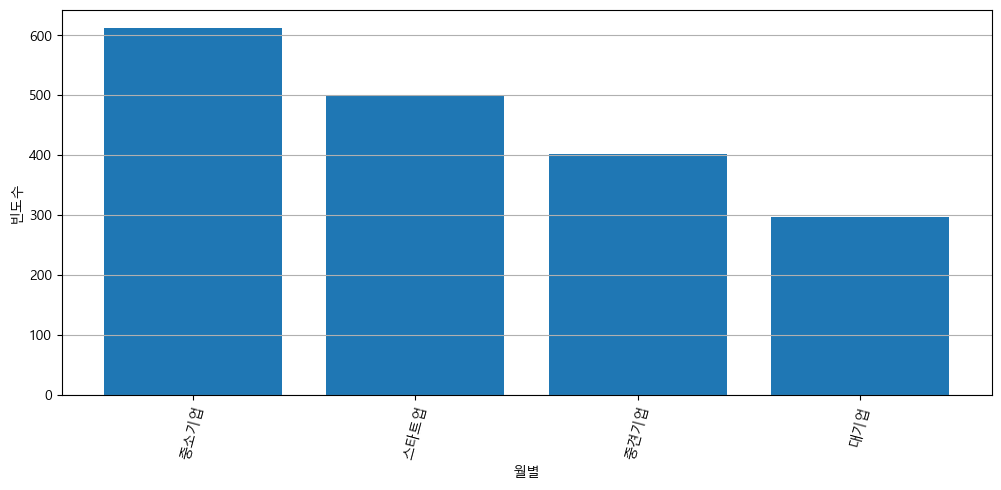

In [ ]:
plt.figure(figsize = (12, 5))
plt.xlabel('월별')
plt.ylabel('빈도수')
plt.grid(True, axis='y')
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

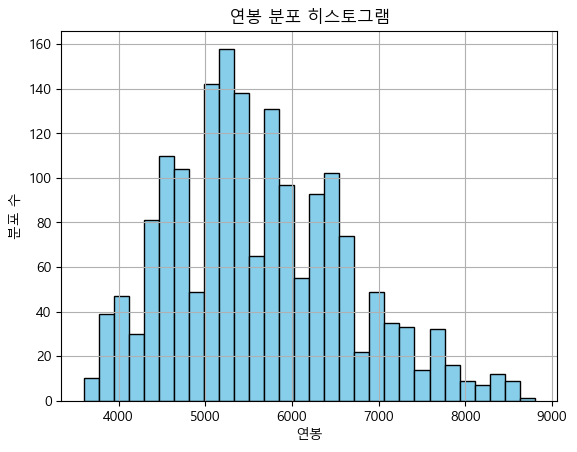

In [ ]:
#4-9 연봉 분포 히스토그램
data_clean['salary'].hist(bins=30, color='skyblue', edgecolor='black')
plt.grid(True, axis='y')
plt.title('연봉 분포 히스토그램')
plt.xlabel('연봉')
plt.ylabel('분포 수')
plt.show()

In [ ]:
#4-10 회사규모별 평균연봉
count = Counter(data_clean['company_size'])
word_count = dict()
data_clean['salary'] = pd.to_numeric(data_clean['salary'], errors='coerce')
normal = data_clean.groupby('company_size')['salary'].mean()
#20개까지만
for tag, counts in normal.items():
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

대기업 : 6263
스타트업 : 5566
중견기업 : 5782
중소기업 : 5267


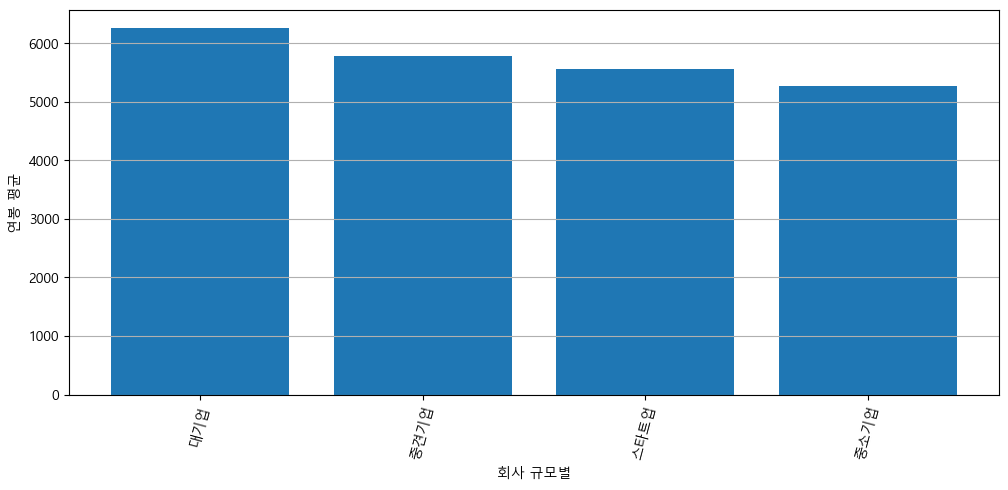

In [ ]:
plt.figure(figsize = (12, 5))
plt.xlabel('회사 규모별')
plt.ylabel('연봉 평균')
plt.grid(True, axis='y')
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

In [ ]:
data_clean.head(0)

,posting_id,company,job,industry,region,experience,required_years,salary,education,employment_type,...,skill,posting_date,posting_month,deadline_days,openings,applicants,welfare_score,description,month,refined_skill


In [ ]:
# 회사규모별 평균연봉
count = Counter(data_clean['company_size'])
word_count = dict()
data_clean['salary'] = pd.to_numeric(data_clean['salary'], errors='coerce')
normal = data_clean.groupby(['industry','company_size'])['salary'].mean()
#20개까지만
for tag, counts in normal.items():
    if(len(str(tag))>1):
        word_count[tag] = counts
        # print("%s : %d" % (tag, counts))

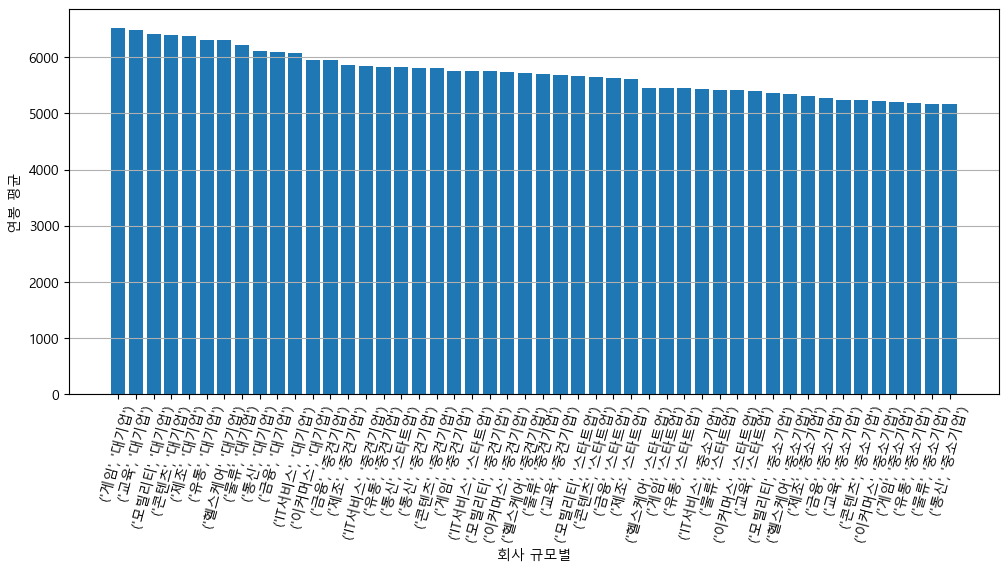

In [39]:
plt.figure(figsize = (12, 5))
plt.xlabel('회사 규모별')
plt.ylabel('연봉 평균')
plt.grid(True, axis='y')
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

IT서비스 : 5709
게임 : 5594
교육 : 5610
금융 : 5633
모빌리티 : 5647
물류 : 5587
유통 : 5606
이커머스 : 5503
제조 : 5708
콘텐츠 : 5677
통신 : 5653
헬스케어 : 5594


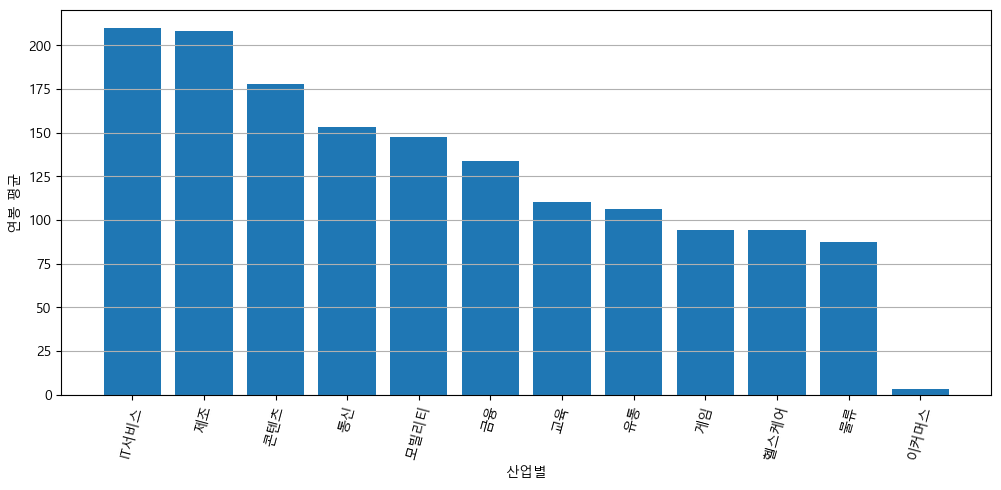

In [44]:
# 회사규모별 평균연봉
count = Counter(data_clean['company_size'])
word_count = dict()
data_clean['salary'] = pd.to_numeric(data_clean['salary'], errors='coerce')
normal = data_clean.groupby(['industry'])['salary'].mean()
#20개까지만
for tag, counts in normal.items():
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))
plt.figure(figsize = (12, 5))
plt.xlabel('산업별')
plt.ylabel('연봉 평균')
plt.grid(True, axis='y')
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
sorted_Values_sub = [v - 5500 for v in sorted_Values]
plt.bar(range(len(word_count)), sorted_Values_sub, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

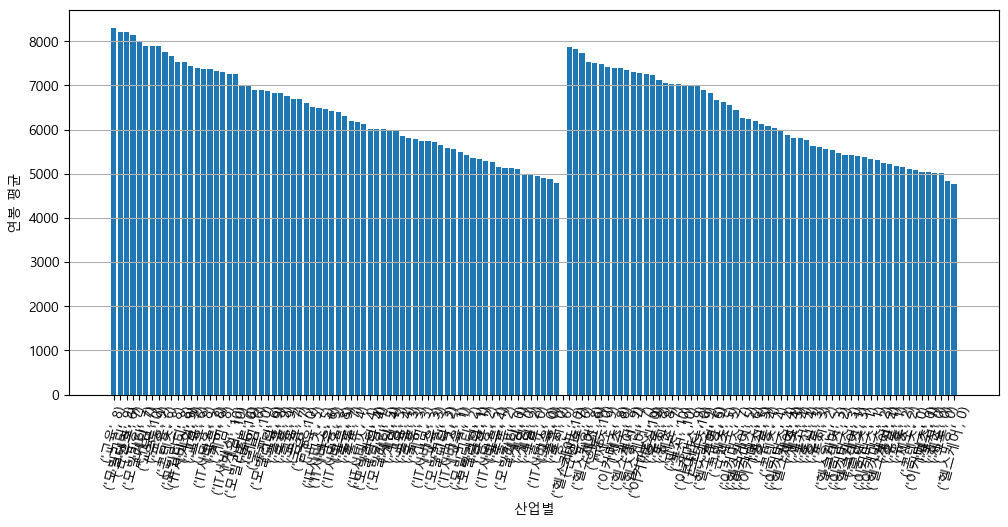

In [46]:
# 회사규모별 평균연봉
count = Counter(data_clean['company_size'])
word_count = dict()
data_clean['salary'] = pd.to_numeric(data_clean['salary'], errors='coerce')
normal = data_clean.groupby(['industry','required_years'])['salary'].mean()
#20개까지만
for tag, counts in normal.items():
    if(len(str(tag))>1):
        word_count[tag] = counts
        # print("%s : %d" % (tag, counts))
plt.figure(figsize = (12, 5))
plt.xlabel('산업별')
plt.ylabel('연봉 평균')
plt.grid(True, axis='y')
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
# sorted_Values_sub = [v - 5500 for v in sorted_Values]
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()